In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
df=pd.read_csv('Algerian_forest_fires_dataset.csv')

In [3]:
df.head()

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,7.0,6.0,2012.0,33.0,54.0,13.0,0.0,88.2,9.9,30.5,6.4,10.9,7.2,fire,0
1,8.0,6.0,2012.0,30.0,73.0,15.0,0.0,86.6,12.1,38.3,5.6,13.5,7.1,fire,0
2,9.0,6.0,2012.0,25.0,88.0,13.0,0.2,52.9,7.9,38.8,0.4,10.5,0.3,not fire,0
3,10.0,6.0,2012.0,28.0,79.0,12.0,0.0,73.2,9.5,46.3,1.3,12.6,0.9,not fire,0
4,11.0,6.0,2012.0,31.0,65.0,14.0,0.0,84.5,12.5,54.3,4.0,15.8,5.6,fire,0


In [4]:
df.columns

Index(['day', 'month', 'year', 'Temperature', 'RH', 'Ws', 'Rain', 'FFMC',
       'DMC', 'DC', 'ISI', 'BUI', 'FWI', 'Classes', 'Region'],
      dtype='object')

In [5]:
##drop month day year
df.drop(['day', 'month', 'year'],axis=1,inplace=True)

In [6]:
df.head()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,33.0,54.0,13.0,0.0,88.2,9.9,30.5,6.4,10.9,7.2,fire,0
1,30.0,73.0,15.0,0.0,86.6,12.1,38.3,5.6,13.5,7.1,fire,0
2,25.0,88.0,13.0,0.2,52.9,7.9,38.8,0.4,10.5,0.3,not fire,0
3,28.0,79.0,12.0,0.0,73.2,9.5,46.3,1.3,12.6,0.9,not fire,0
4,31.0,65.0,14.0,0.0,84.5,12.5,54.3,4.0,15.8,5.6,fire,0


In [7]:
df['Classes'].value_counts()

Classes
fire        136
not fire     99
Name: count, dtype: int64

In [8]:
## ENcoding
df['Classes']=np.where(df['Classes'].str.contains("not fire"),0,1)

In [9]:
df.head()


,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,33.0,54.0,13.0,0.0,88.2,9.9,30.5,6.4,10.9,7.2,1,0
1,30.0,73.0,15.0,0.0,86.6,12.1,38.3,5.6,13.5,7.1,1,0
2,25.0,88.0,13.0,0.2,52.9,7.9,38.8,0.4,10.5,0.3,0,0
3,28.0,79.0,12.0,0.0,73.2,9.5,46.3,1.3,12.6,0.9,0,0
4,31.0,65.0,14.0,0.0,84.5,12.5,54.3,4.0,15.8,5.6,1,0


In [10]:
df.tail()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
230,30.0,65.0,14.0,0.0,85.4,16.0,44.5,4.5,16.9,6.5,1,1
231,28.0,87.0,15.0,4.4,41.1,6.5,8.0,0.1,6.2,0.0,0,1
232,27.0,87.0,29.0,0.5,45.9,3.5,7.9,0.4,3.4,0.2,0,1
233,24.0,54.0,18.0,0.1,79.7,4.3,15.2,1.7,5.1,0.7,0,1
234,24.0,64.0,15.0,0.2,67.3,3.8,16.5,1.2,4.8,0.5,0,1


In [11]:
df['Classes'].value_counts()

Classes
1    136
0     99
Name: count, dtype: int64

In [12]:
## independent and depemdent features
X=df.drop('FWI',axis=1)
y=df['FWI']

In [13]:
X.head()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,Classes,Region
0,33.0,54.0,13.0,0.0,88.2,9.9,30.5,6.4,10.9,1,0
1,30.0,73.0,15.0,0.0,86.6,12.1,38.3,5.6,13.5,1,0
2,25.0,88.0,13.0,0.2,52.9,7.9,38.8,0.4,10.5,0,0
3,28.0,79.0,12.0,0.0,73.2,9.5,46.3,1.3,12.6,0,0
4,31.0,65.0,14.0,0.0,84.5,12.5,54.3,4.0,15.8,1,0


In [14]:
y


0      7.2
1      7.1
2      0.3
3      0.9
4      5.6
      ... 
230    6.5
231    0.0
232    0.2
233    0.7
234    0.5
Name: FWI, Length: 235, dtype: float64

In [15]:
# train test split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=42)

In [16]:
X_train.shape,X_test.shape

((176, 11), (59, 11))

In [17]:
## feature selectoin based on correlaltion
X_train.corr()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,Classes,Region
Temperature,1.000000,-0.663181,-0.341034,-0.304976,0.687900,0.500633,0.377835,0.632806,0.468647,0.536850,0.280293
RH,-0.663181,1.000000,0.252440,0.201441,-0.622521,-0.358834,-0.184720,-0.688830,-0.303201,-0.406549,-0.378049
Ws,-0.341034,0.252440,1.000000,0.199025,-0.217854,-0.004760,0.100979,-0.058089,0.035640,-0.106848,-0.226497
Rain,-0.304976,0.201441,0.199025,1.000000,-0.565840,-0.282521,-0.310759,-0.344504,-0.296998,-0.380162,0.003339
FFMC,0.687900,-0.622521,-0.217854,-0.565840,1.000000,0.586060,0.505896,0.728906,0.573903,0.761524,0.163198
DMC,0.500633,-0.358834,-0.004760,-0.282521,0.586060,1.000000,0.882494,0.661390,0.983923,0.589159,0.125306
DC,0.377835,-0.184720,0.100979,-0.310759,0.505896,0.882494,1.000000,0.513083,0.950160,0.552443,-0.145352
ISI,0.632806,-0.688830,-0.058089,-0.344504,0.728906,0.661390,0.513083,1.000000,0.622601,0.712079,0.189836
BUI,0.468647,-0.303201,0.035640,-0.296998,0.573903,0.983923,0.950160,0.622601,1.000000,0.592131,0.022330
Classes,0.536850,-0.406549,-0.106848,-0.380162,0.761524,0.589159,0.552443,0.712079,0.592131,1.000000,0.075135


<Axes: >

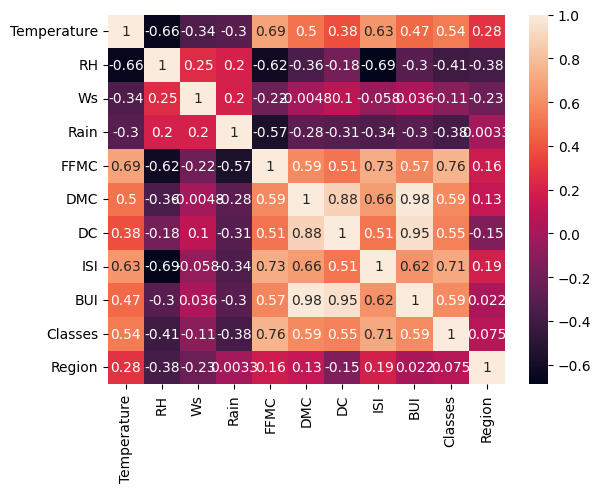

In [18]:
## check for multicollinearity
plt.Figure(figsize=(12,10))
corr=X_train.corr()
sns.heatmap(corr,annot=True)

In [19]:
def correlation(dataset,threshold):
    col_corr = set()
    corr_matrix =dataset.corr()
    for i in range(len(corr_matrix.columns)):
        for j in range(1):
            if abs(corr_matrix.iloc[i,j]) > threshold:
                colname = corr_matrix.columns[i]
                col_corr.add(colname)
        return col_corr


In [20]:
## threshold--Domain Expertise
corr_features=correlation(X_train,0.85)

In [21]:
X_train.drop(corr_features,axis=1,inplace=True)
X_test.drop(corr_features,axis=1,inplace=True)
X_train.shape,X_test.shape



((176, 10), (59, 10))

In [22]:
##feature Scaling or standardization

from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [23]:
X_train_scaled

array([[-0.33321186, -0.57864854, -0.37633716, ..., -0.19808838,
         0.8418657 , -0.96647087],
       [-0.39977859,  0.20175102, -0.37633716, ...,  0.47791672,
         0.8418657 ,  1.03469234],
       [-0.2000784 ,  0.20175102, -0.37633716, ...,  0.17512277,
         0.8418657 ,  1.03469234],
       ...,
       [ 0.59872233,  0.59195081, -0.22892913, ..., -0.83888488,
        -1.18783791, -0.96647087],
       [-0.53291205, -0.57864854,  1.14687913, ..., -0.45863201,
        -1.18783791,  1.03469234],
       [-0.6660455 , -0.57864854, -0.37633716, ..., -0.65580017,
         0.8418657 , -0.96647087]], shape=(176, 10))

Box plots to understand effect of standard scaler

Text(0.5, 1.0, 'X_train After Scaling')

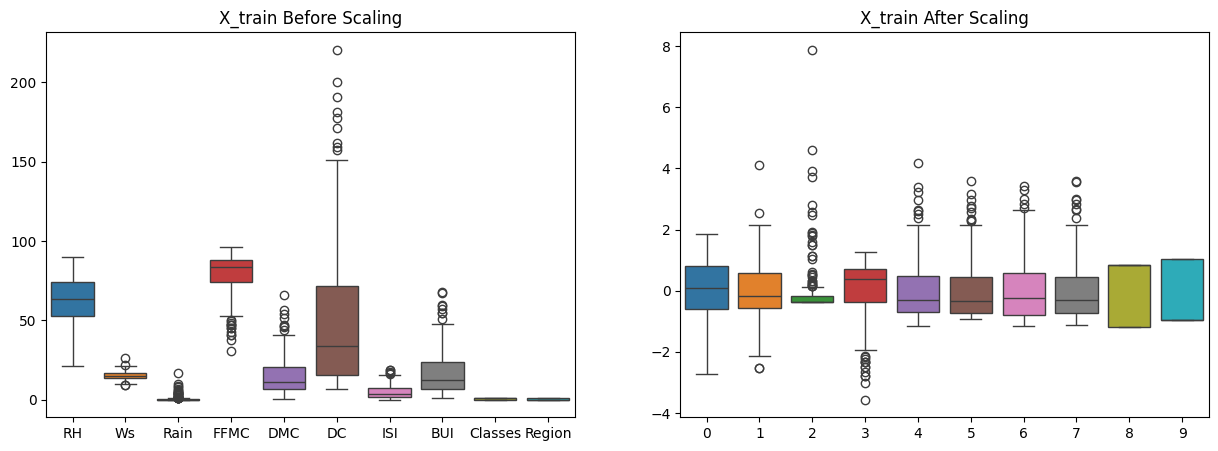

In [24]:

# 4. Create box plots
# ------------------------------------------
plt.figure(figsize=(15, 5))

# Before scaling
plt.subplot(1, 2, 1)
sns.boxplot(data=X_train)
plt.title('X_train Before Scaling')


# After scaling
plt.subplot(1, 2, 2)
sns.boxplot(data=X_train_scaled)
plt.title('X_train After Scaling')



In [25]:
 ##LINEAR REGRESSION MODEOL

mean_absolute_error 45.218614631213455
R2 Score -59.950545327860425


c:\Users\Admin\Downloads\code\venv\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


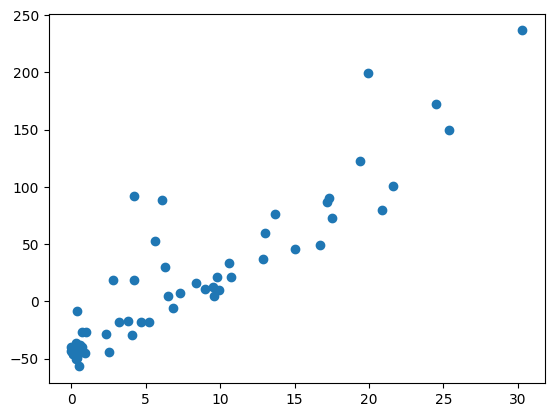

In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
linreg=LinearRegression()
linreg.fit(X_train_scaled,y_train)
y_pred=linreg.predict(X_test)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("mean_absolute_error",mae)
print("R2 Score",score)
plt.scatter(y_test,y_pred)

In [27]:
##Lasso Regression Model

mean_absolute_error 67.58567061447957
R2 Score -109.293284047512


c:\Users\Admin\Downloads\code\venv\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but Lasso was fitted without feature names
  warnings.warn(


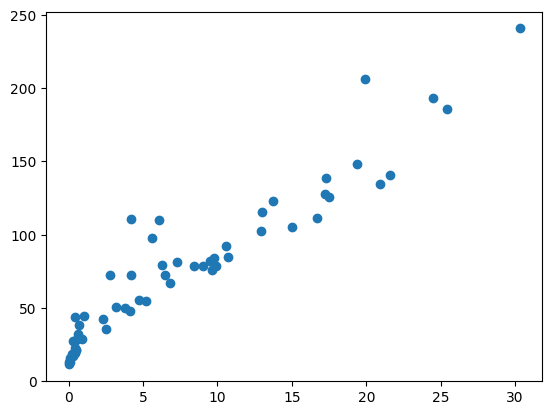

In [28]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
Lasso=Lasso()
Lasso.fit(X_train_scaled,y_train)
y_pred=Lasso.predict(X_test)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("mean_absolute_error",mae)
print("R2 Score",score)
plt.scatter(y_test,y_pred)

In [29]:
from sklearn.linear_model import LassoCV
lasso = LassoCV(cv=5)
lasso.fit(X_train_scaled, y_train)

,eps,0.001
,n_alphas,'deprecated'
,alphas,'warn'
,fit_intercept,True
,precompute,'auto'
,max_iter,1000
,tol,0.0001
,copy_X,True
,cv,5
,verbose,False
,n_jobs,None


In [30]:
lasso.predict(X_test_scaled)

array([ 7.24321182,  2.1879655 ,  0.58782283, -0.3231152 ,  0.11153634,
        0.91591494, 22.82485017, -0.0296775 ,  7.87374283,  2.28900364,
       19.87437382,  1.07384357,  1.9897371 ,  3.34499372,  8.63643768,
        9.57856229, 10.22015993,  4.26594716, 12.93342353,  0.06900874,
       -0.14797481, -0.59946974, -0.34423381, -0.11111474, 16.40277362,
       -0.1797398 , -0.60906126, 10.52126054,  8.53758794,  8.26730985,
        5.05669305,  5.29769454,  4.67644854,  9.07487841, 12.18135696,
        8.64991958, 23.22895871,  4.07237892,  4.85458387, 20.63006196,
       12.4201618 , 17.44956247, 16.68381201,  6.7264744 , 28.40888854,
        6.46281526, 21.01023112, -0.79008739,  9.67032448, 14.59776772,
        7.04767734, -0.72323978, 16.19439342,  9.3776013 ,  1.53158392,
       -0.31176753,  1.73284657, 15.74580276,  0.63981174])

In [31]:
lasso.alpha_

np.float64(0.021952744345651466)

In [32]:
lasso.alphas_

array([6.70405093, 6.25222033, 5.83084161, 5.4378624 , 5.07136867,
       4.7295754 , 4.41081784, 4.11354348, 3.83630442, 3.57775034,
       3.33662194, 3.11174479, 2.90202361, 2.70643693, 2.52403214,
       2.35392082, 2.19527443, 2.04732029, 1.90933775, 1.78065478,
       1.6606446 , 1.54872272, 1.44434399, 1.34700004, 1.25621674,
       1.17155194, 1.09259326, 1.01895613, 0.9502819 , 0.88623608,
       0.82650673, 0.77080294, 0.71885341, 0.67040509, 0.62522203,
       0.58308416, 0.54378624, 0.50713687, 0.47295754, 0.44108178,
       0.41135435, 0.38363044, 0.35777503, 0.33366219, 0.31117448,
       0.29020236, 0.27064369, 0.25240321, 0.23539208, 0.21952744,
       0.20473203, 0.19093377, 0.17806548, 0.16606446, 0.15487227,
       0.1444344 , 0.1347    , 0.12562167, 0.11715519, 0.10925933,
       0.10189561, 0.09502819, 0.08862361, 0.08265067, 0.07708029,
       0.07188534, 0.06704051, 0.0625222 , 0.05830842, 0.05437862,
       0.05071369, 0.04729575, 0.04410818, 0.04113543, 0.03836

In [33]:
lasso.mse_path_

array([[61.07227432, 41.07619997, 38.48422806, 78.50171621, 49.32537913],
       [56.70510862, 36.91678438, 33.40631112, 78.50171621, 44.23841069],
       [50.45429116, 33.07081966, 28.85625323, 72.32069603, 38.76906241],
       [44.56172043, 28.94212288, 24.97125383, 65.68045687, 34.00367313],
       [39.40071249, 25.35186543, 21.65997804, 59.82197494, 29.85114415],
       [34.87831735, 22.22958179, 18.84304361, 54.64902898, 26.23216271],
       [30.91362047, 19.51472421, 16.45163661, 50.07755299, 23.07772728],
       [27.43591741, 17.15396647, 14.42670866, 44.29258372, 20.32777239],
       [24.38409757, 15.1011538 , 12.71896165, 38.82873963, 17.93008075],
       [21.70435304, 13.31614546, 11.3003885 , 34.07518907, 15.83915081],
       [19.34993429, 11.76403112, 10.10792613, 29.93869469, 14.01539993],
       [17.28006552, 10.41424509,  9.10939349, 26.3514305 , 12.42437598],
       [15.45917433,  9.2408218 ,  8.27690596, 23.22455494, 11.03607669],
       [13.8412873 ,  8.22055829,  7.5

mean_absolute_error 0.763252975167337
R2 Score 0.979876285066915


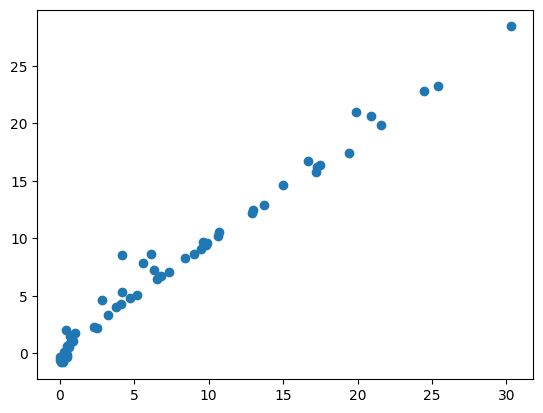

In [34]:
y_pred=lasso.predict(X_test_scaled)
plt.scatter(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("mean_absolute_error",mae)
print("R2 Score",score)

In [35]:
## Ridge Regression Model

mean_absolute_error 51.408221001994804
R2 Score -82.02886147588016


c:\Users\Admin\Downloads\code\venv\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but Ridge was fitted without feature names
  warnings.warn(


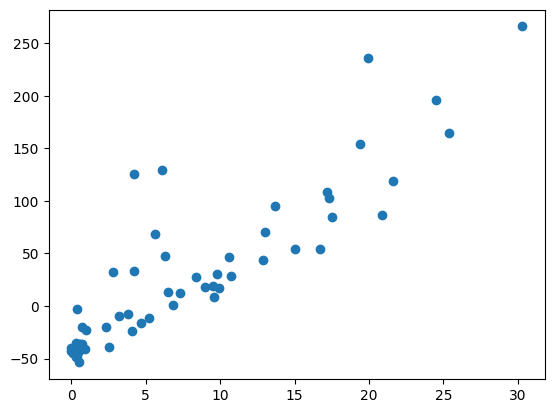

In [36]:
from sklearn.linear_model import Ridge 
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
Ridge =Ridge ()
Ridge .fit(X_train_scaled,y_train)
y_pred=Ridge .predict(X_test)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("mean_absolute_error",mae)
print("R2 Score",score)
plt.scatter(y_test,y_pred)

mean_absolute_error 1.0079232555935445
R2 Score 0.9675520012653349


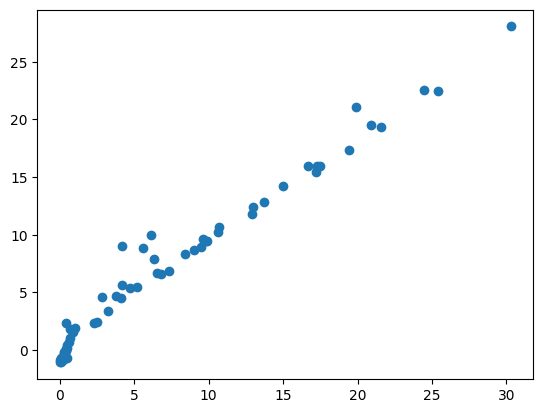

In [37]:
from sklearn.linear_model import RidgeCV
ridgecv=RidgeCV(cv=5)
ridgecv.fit(X_train_scaled,y_train)
y_pred=ridgecv.predict(X_test_scaled)
plt.scatter(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("mean_absolute_error",mae)
print("R2 Score",score)

In [38]:
ridgecv.get_params()

{'alpha_per_target': False,
 'alphas': (0.1, 1.0, 10.0),
 'cv': 5,
 'fit_intercept': True,
 'gcv_mode': None,
 'scoring': None,
 'store_cv_results': False}

In [39]:
## Elasticnet REgression

mean_absolute_error 79.04702312817996
R2 Score -188.56211952468547


c:\Users\Admin\Downloads\code\venv\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(


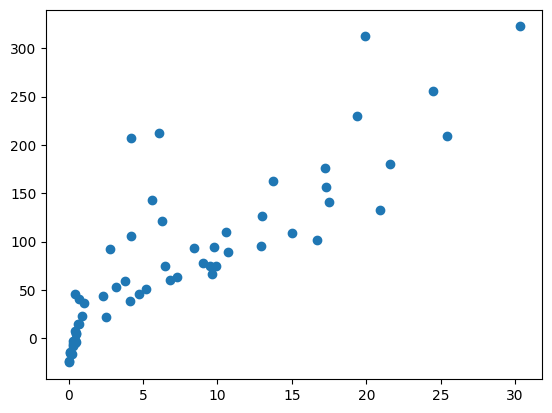

In [40]:
from sklearn.linear_model import ElasticNet 
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
ElasticNet =ElasticNet ()
ElasticNet .fit(X_train_scaled,y_train)
y_pred=ElasticNet .predict(X_test)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("mean_absolute_error",mae)
print("R2 Score",score)
plt.scatter(y_test,y_pred)

mean_absolute_error 0.8808149466646154
R2 Score 0.9739947126604259


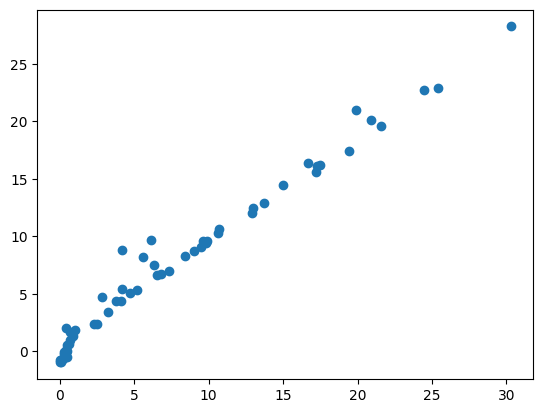

In [41]:
from sklearn.linear_model import ElasticNetCV
elasticcv=ElasticNetCV(cv=5)
elasticcv.fit(X_train_scaled,y_train)
y_pred=elasticcv.predict(X_test_scaled)
plt.scatter(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("mean_absolute_error",mae)
print("R2 Score",score)

In [42]:
elasticcv.alpha_


np.float64(0.047078416390029056)

In [43]:
elasticcv.copy_X


True

In [44]:
elasticcv.fit_intercept

True

In [45]:
elasticcv.coef_

array([-0.32079242, -0.01036985,  0.00930725, -0.5349717 ,  1.69847945,
        0.5916387 ,  4.30046736,  1.36938385,  0.28847632, -0.18037388])

In [46]:
scaler

,copy,True
,with_mean,True
,with_std,True


In [47]:
Ridge

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [49]:
import pickle
pickle.dump(scaler,open('scaler.pk1','wb'))
pickle.dump(Ridge,open('Ridge.pk1','wb'))